# Project 1: Video game sales and reviews

I compare sales and reviews, then group similar releases. Each row is one game on one platform. Sales are in millions of copies, using December 2016 data [1]. See the [dataset selection notebook](dataset_selection.ipynb) for the columns.

Use Python 3.12, install `python -m pip install -r proj1/requirements.txt` from the project folder, then run all cells in Jupyter. The first code cell downloads the data.

In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

# Download version 2 so every run uses the same data.
url = "https://www.kaggle.com/api/v1/datasets/download/rush4ratio/video-game-sales-with-ratings?datasetVersionNumber=2"
with urlopen(url, timeout=30) as response:
    with ZipFile(BytesIO(response.read())) as archive:
        with archive.open("Video_Games_Sales_as_at_22_Dec_2016.csv") as csv:
            raw = pd.read_csv(csv)

print(f"{len(raw):_} rows, {raw.shape[1]} columns")
display(raw.head())

16_719 rows, 16 columns


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Check and clean the data

In [2]:
games = raw.dropna(subset=["Name", "Genre"]).copy()
# 'tbd' means no user score is available.
games["User_Score"] = pd.to_numeric(games["User_Score"].replace("tbd", np.nan))
regions = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
sales = regions + ["Global_Sales"]
scores = ["Critic_Score", "User_Score"]
counts = ["Critic_Count", "User_Count"]

missing = pd.DataFrame({
    "Missing": games.isna().sum(),
    "Missing %": games.isna().mean().mul(100).round(1),
})
display(missing)
print(f"After cleaning: {len(games):_} rows")

,Missing,Missing %
Name,0,0.0
Platform,0,0.0
Year_of_Release,269,1.6
Genre,0,0.0
Publisher,54,0.3
NA_Sales,0,0.0
EU_Sales,0,0.0
JP_Sales,0,0.0
Other_Sales,0,0.0
Global_Sales,0,0.0


After cleaning: 16_717 rows


I remove two rows missing both name and genre. User scores are missing from 54.6% of the remaining rows and critic scores from 51.3%. I keep these releases for sales analysis and use only complete reviews for grouping.

## 2. Look at sales and reviews

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,User_Score,Critic_Count,User_Count
Rows with a value,16717.00,16717.00,16717.00,16717.00,16717.00,8137.00,7590.00,8137.00,7590.00
Average,0.26,0.15,0.08,0.05,0.53,68.97,7.13,26.36,162.23
median,0.08,0.02,0.00,0.01,0.17,71.00,7.50,21.00,24.00
min,0.00,0.00,0.00,0.00,0.01,13.00,0.00,3.00,4.00
max,41.36,28.96,10.22,10.57,82.53,98.00,9.70,113.00,10665.00


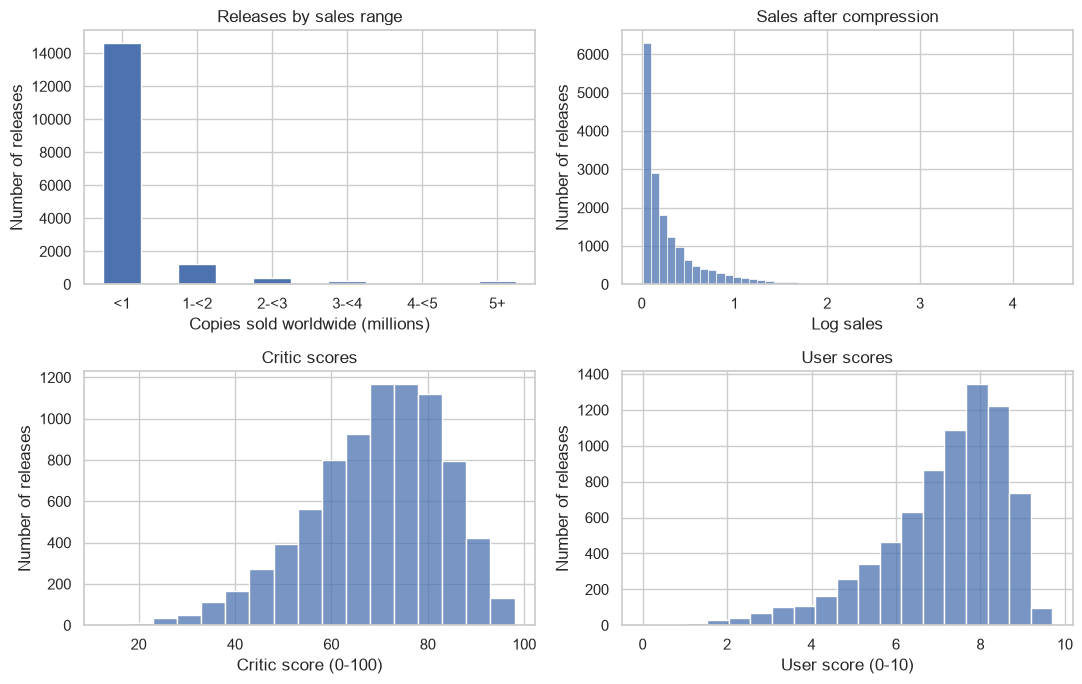

In [3]:
display(
    games[sales + scores + counts]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(index={"count": "Rows with a value", "mean": "Average"})
    .round(2)
)

# Reuse compressed sales in this plot and in grouping.
games["Log_sales"] = np.log1p(games["Global_Sales"])
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sales_ranges = pd.cut(
    games["Global_Sales"], bins=[0, 1, 2, 3, 4, 5, np.inf], right=False,
    labels=["<1", "1-<2", "2-<3", "3-<4", "4-<5", "5+"],
)
sales_ranges.value_counts(sort=False).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(xlabel="Copies sold worldwide (millions)", ylabel="Number of releases", title="Releases by sales range")
sns.histplot(data=games, x="Log_sales", bins=50, ax=axes[0, 1])
axes[0, 1].set(xlabel="Log sales", ylabel="Number of releases", title="Sales after compression")
sns.histplot(data=games, x="Critic_Score", binwidth=5, ax=axes[1, 0])
axes[1, 0].set(title="Critic scores", xlabel="Critic score (0-100)", ylabel="Number of releases")
sns.histplot(data=games, x="User_Score", binwidth=0.5, ax=axes[1, 1])
axes[1, 1].set(title="User scores", xlabel="User score (0-10)", ylabel="Number of releases")
plt.tight_layout()
plt.show()

Median sales are 0.17 million copies, the average is 0.53 million and the maximum is 82.53 million. Most releases sold fewer than one million copies. The log(1 + sales) calculation compresses large values for easier comparison.

Median critic and user scores are 71 and 7.5. Both score charts extend farther toward low scores.

### Sales by genre and region

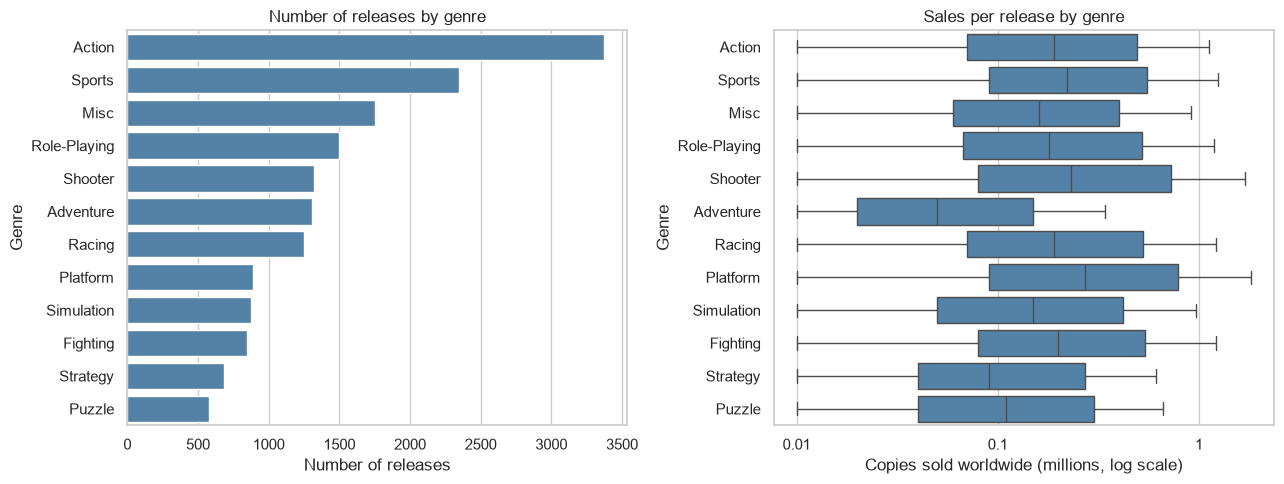

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,50.4,29.8,9.3,10.6
Adventure,44.3,26.7,22.0,6.9
Fighting,49.9,22.4,19.5,8.1
Misc,50.7,26.5,13.5,9.3
Platform,53.8,24.2,15.8,6.2
Puzzle,50.7,20.6,23.6,5.1
Racing,49.3,32.5,7.8,10.4
Role-Playing,35.4,20.2,38.0,6.4
Shooter,56.3,30.2,3.7,9.9


In [4]:
genre_order = games["Genre"].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=games, y="Genre", order=genre_order, ax=axes[0], color="steelblue")
axes[0].set(title="Number of releases by genre", xlabel="Number of releases")
# Hide dots for unusually high or low sales to keep the boxes readable.
sns.boxplot(data=games, y="Genre", x="Global_Sales", order=genre_order, ax=axes[1], showfliers=False, color="steelblue")
axes[1].set(xscale="log", xlabel="Copies sold worldwide (millions, log scale)", title="Sales per release by genre")
# Use regular numbers instead of powers of ten on the axis.
axes[1].xaxis.set_major_formatter("{x:g}")
plt.tight_layout()
plt.show()

regional_sales = games.groupby("Genre")[regions].sum()
display(regional_sales.div(regional_sales.sum(axis=1), axis=0).mul(100).round(1))

Action has the most releases. Median sales are 0.27 million copies for Platform, 0.19 million for Action and 0.05 million for Adventure, the lowest. These compare sales per release, not profit. Sales vary widely within genres. All box plots hide dots for unusual values, but keep those releases in the calculations.

Japan accounts for 38.0% of Role-Playing sales and 3.7% of Shooter sales. These differences are why I use regional shares alongside total sales.

### Review scores and sales

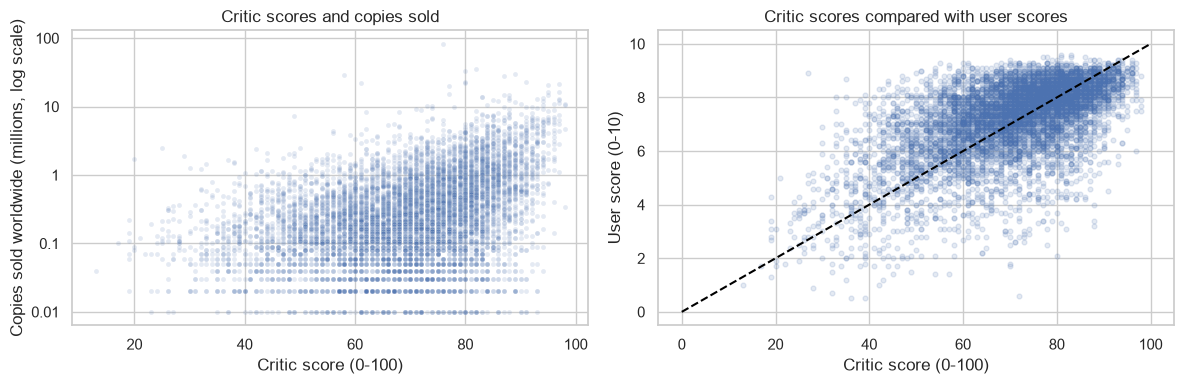

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=games, x="Critic_Score", y="Global_Sales", alpha=0.15, s=12, ax=axes[0])
axes[0].set(yscale="log", xlabel="Critic score (0-100)", ylabel="Copies sold worldwide (millions, log scale)", title="Critic scores and copies sold")
axes[0].yaxis.set_major_formatter("{x:g}")
axes[1].scatter(games["Critic_Score"], games["User_Score"], alpha=0.15, s=12)
axes[1].plot([0, 100], [0, 10], color="black", linestyle="--")
axes[1].set(xlabel="Critic score (0-100)", ylabel="User score (0-10)", title="Critic scores compared with user scores")
plt.tight_layout()
plt.show()

Higher critic scores tend to come with higher sales, with plenty of variation. This does not prove that reviews cause sales.

The dashed line compares matching ratings on the two score scales. Points above it have higher user ratings, and points below have higher critic ratings.

### Relationships between columns

Spearman correlation compares the order of values. Each pair uses rows with both values available.

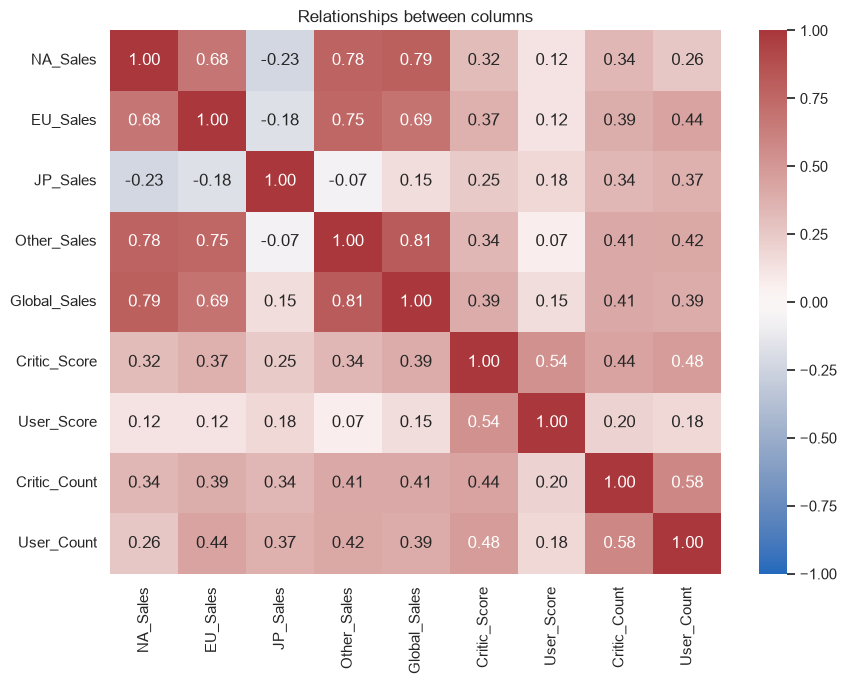

In [6]:
correlations = games[sales + scores + counts].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Relationships between columns")
plt.tight_layout()
plt.show()

Global sales correlate at 0.79 with North American sales, 0.69 with European sales and 0.15 with Japanese sales.

Critic scores relate more strongly to global sales than user scores, 0.39 compared with 0.15. The correlation between critic and user scores is 0.54, showing partial agreement.

## 3. Prepare the data for grouping

### Biggest sellers

The table below shows the biggest sellers. I keep releases such as *Wii Sports* because high sales can be valid. The log calculation reduces their influence on grouping.

In [7]:
display(games.nlargest(5, "Global_Sales")[["Name", "Platform", "Global_Sales", "Critic_Score", "User_Score"]])

,Name,Platform,Global_Sales,Critic_Score,User_Score
0,Wii Sports,Wii,82.53,76.0,8.0
1,Super Mario Bros.,NES,40.24,NaN,NaN
2,Mario Kart Wii,Wii,35.52,82.0,8.3
3,Wii Sports Resort,Wii,32.77,80.0,8.0
4,Pokemon Red/Pokemon Blue,GB,31.37,NaN,NaN


### Extra columns

| Column | Calculation |
| --- | --- |
| `NA_share` | North American sales / total regional sales |
| `JP_share` | Japanese sales / total regional sales |
| `Review_gap` | 10 × user score − critic score. Positive values mean users rated the game higher. |
| `Log_sales` | log(1 + global sales) |

In [8]:
clustered = games.dropna(subset=scores).copy()
regional_total = clustered[regions].sum(axis=1)
clustered["NA_share"] = clustered["NA_Sales"] / regional_total
clustered["JP_share"] = clustered["JP_Sales"] / regional_total
clustered["Review_gap"] = 10 * clustered["User_Score"] - clustered["Critic_Score"]

features = ["Log_sales", "NA_share", "JP_share", "Critic_Score", "User_Score"]
X = StandardScaler().fit_transform(clustered[features])
print(f"Releases used for grouping: {len(clustered):,} of {len(games):,} ({len(clustered) / len(games):.1%})")

Releases used for grouping: 7,017 of 16,717 (42.0%)


I compare log sales, North American and Japanese sales shares, critic scores and user scores. StandardScaler puts these columns on a common scale so their different units do not dominate the grouping [2].

`Review_gap` repeats the scores, and separate regional sales repeat total sales information. I use two regional shares to keep comparisons simple. Genre and platform describe the groups afterward; publisher and developer names would add hundreds of categories.

I use only releases with both review scores. Filling missing reviews with the median would make many games artificially similar.

In [9]:
genre_mix = pd.DataFrame({
    "All releases (%)": games["Genre"].value_counts(normalize=True).mul(100),
    "With both reviews (%)": clustered["Genre"].value_counts(normalize=True).mul(100),
}).round(1)
display(genre_mix)

,All releases (%),With both reviews (%)
Genre,,
Action,20.2,23.9
Adventure,7.8,3.8
Fighting,5.1,5.5
Misc,10.5,5.6
Platform,5.3,5.8
Puzzle,3.5,1.7
Racing,7.5,8.5
Role-Playing,9.0,10.3
Shooter,7.9,12.6


Grouping keeps 7,017 releases, 42.0% of the cleaned data. Shooters rise from 7.9% to 12.6%, while Misc falls from 10.5% to 5.6%. Requiring both review scores changes the genre mix.

## 4. Try two ways of grouping games

K-means puts each game with the nearest group center and updates the centers as it goes. Ward starts with each game on its own, then gradually combines groups while keeping the games within each group as similar as possible [3]. Both use the same five columns.

I try two to six groups and choose the highest average silhouette score for each method. This score compares how close games are to their own group with how close they are to the nearest other group. Higher scores are better, and scores near zero suggest overlap [4]. I use all selected releases to calculate the scores.

,K-means silhouette,Ward silhouette
k,,
2,0.223,0.268
3,0.268,0.265
4,0.273,0.237
5,0.280,0.222
6,0.242,0.163


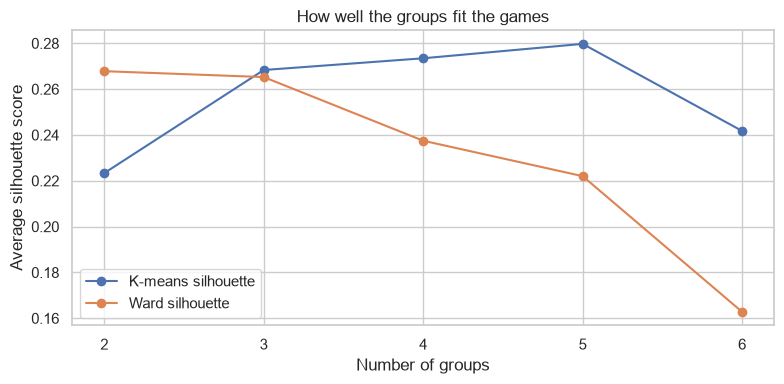

In [10]:
results = []
for k in range(2, 7):
    # A fixed seed makes the K-means results repeatable.
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    results.append({
        "k": k,
        "K-means silhouette": silhouette_score(X, kmeans),
        "Ward silhouette": silhouette_score(X, ward),
    })
results = pd.DataFrame(results).set_index("k")
display(results.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
results.plot(ax=ax, marker="o")
ax.set(title="How well the groups fit the games", xlabel="Number of groups", ylabel="Average silhouette score", xticks=results.index)
plt.tight_layout()
plt.show()

K-means scores highest with five groups, 0.280. Ward scores highest with two groups, 0.268, close to three groups at 0.265.

I use the highest-scoring result for each method. The groups overlap, and counts outside two to six were not tested.

In [11]:
best_kmeans_k = int(results["K-means silhouette"].idxmax())
best_ward_k = int(results["Ward silhouette"].idxmax())
clustered["K-means"] = KMeans(n_clusters=best_kmeans_k, n_init=10, random_state=42).fit_predict(X)
clustered["Ward"] = AgglomerativeClustering(n_clusters=best_ward_k, linkage="ward").fit_predict(X)
methods = ["K-means", "Ward"]

## 5. Look at the groups

The tables show group medians and the most common genre and platform. Group numbers are labels, not rankings.

In [12]:
profile_columns = ["Global_Sales", "NA_share", "JP_share", "Critic_Score", "User_Score", "Review_gap"]
for method in methods:
    print(method)
    groups = clustered.groupby(method)
    profile = groups[profile_columns].median()
    profile.insert(0, "Releases", groups.size())
    for column in ["Genre", "Platform"]:
        profile[column] = groups[column].agg(lambda values: values.value_counts().idxmax())
    display(profile.round(2))

K-means


,Releases,Global_Sales,NA_share,JP_share,Critic_Score,User_Score,Review_gap,Genre,Platform
K-means,,,,,,,,,
0,2955,0.25,0.72,0.00,74.0,7.8,4.0,Action,PS2
1,572,0.29,0.25,0.55,72.0,7.9,6.0,Role-Playing,PS2
2,1393,0.17,0.67,0.00,52.0,5.5,2.0,Action,X360
3,1089,0.17,0.15,0.00,75.0,7.4,-2.0,Action,PC
4,1008,2.13,0.51,0.01,84.0,8.0,-4.0,Action,PS2


Ward


,Releases,Global_Sales,NA_share,JP_share,Critic_Score,User_Score,Review_gap,Genre,Platform
Ward,,,,,,,,,
0,1694,1.34,0.45,0.18,80.0,8.0,1.0,Action,PS2
1,5323,0.21,0.59,0.00,70.0,7.3,2.0,Action,PS2


K-means gives these groups:

- Group 0 has a large North American sales share and good reviews.
- Group 1 has a large Japanese sales share. Role-Playing is its most common genre.
- Group 2 has lower critic and user scores.
- Group 3 has smaller North American and Japanese sales shares. PC is its most common platform.
- Group 4 has higher sales and high critic scores.

Ward's group 0 combines many games with higher sales and larger Japanese sales shares. Group 1 contains most other releases. This split is broader than the five K-means groups.

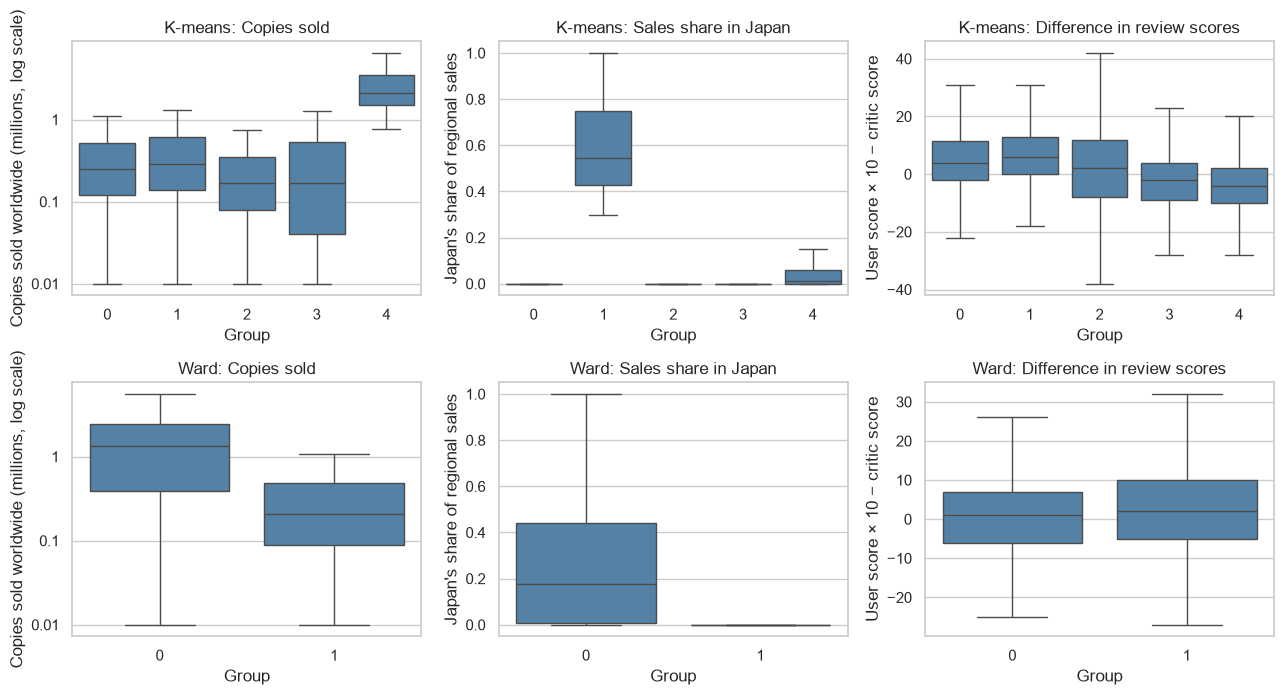

In [13]:
fig, axes = plt.subplots(len(methods), 3, figsize=(13, 7))
for row, method in enumerate(methods):
    for column, feature in enumerate(["Global_Sales", "JP_share", "Review_gap"]):
        sns.boxplot(data=clustered, x=method, y=feature, ax=axes[row, column], showfliers=False, color="steelblue")
    axes[row, 0].set(yscale="log", ylabel="Copies sold worldwide (millions, log scale)", xlabel="Group", title=f"{method}: Copies sold")
    # Use regular numbers instead of powers of ten on the axis.
    axes[row, 0].yaxis.set_major_formatter("{x:g}")
    axes[row, 1].set(ylabel="Japan's share of regional sales", xlabel="Group", title=f"{method}: Sales share in Japan")
    axes[row, 2].set(ylabel="User score × 10 − critic score", xlabel="Group", title=f"{method}: Difference in review scores")
plt.tight_layout()
plt.show()

K-means group 4 has higher sales, while group 1 has a larger Japanese sales share. Review score differences overlap across groups and would separate them poorly on their own.

Ward mainly splits games by sales, with little separation in review score differences.

## References

[1] RUSH4RATIO. *Video Game Sales with Ratings*. Online dataset. Version 2. Kaggle, [no date]. Available from: https://www.kaggle.com/datasets/rush4ratio/video-game-sales-with-ratings. [cited 2026-11-07].

[2] SCIKIT-LEARN DEVELOPERS. *StandardScaler*. Online. Scikit-learn documentation. Available from: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html. [cited 2026-11-07].

[3] SCIKIT-LEARN DEVELOPERS. *Clustering*. Online. Scikit-learn documentation. Available from: https://scikit-learn.org/stable/modules/clustering.html. [cited 2026-11-07].

[4] SCIKIT-LEARN DEVELOPERS. *silhouette_score*. Online. Scikit-learn documentation. Available from: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html. [cited 2026-11-07].

[5] VGCHARTZ. *VGChartz methodology*. Online. Available from: https://www.vgchartz.com/methodology.php. [cited 2026-11-07].

[6] OPENAI. *Codex*. Online AI tool. Model gpt-6.1-sol. 2026. Available from: https://openai.com/codex/. [used 2026-11-07 and 2026-11-09].

### AI assistance

OpenAI Codex, gpt-6.1-sol, helped write the notebooks, generate plots, and check execution [6].

## Summary

Most releases have low sales, with a few big sellers. Regional sales differ by genre, and critic scores relate more strongly to sales than user scores.

Missing reviews leave only 42.0% of cleaned releases for grouping and change the genre mix.

K-means gives five groups and Ward gives two broader groups. They overlap and describe the reviewed releases, rather than fixed categories for every game.